In [7]:
import pandas as pd

file_path = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_en.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4005, 19)


In [8]:
# Display column names
print("Column names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Display basic statistics
print("\nNumerical summary:")
print(df.describe())

# Display first five records
df.head()

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   str    
 2   speaker_1       4005 non-null   str    
 3   all_speakers    4001 non-null   str    
 4   occupations     3483 non-null   str    
 5   about_speakers  3502 non-null   str    
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   str    
 8   published_date  4005 non-null   str    
 9   event           4005 non-null   str    
 10  native_lang     4005 non-null   str    
 11  available_lang  4005 n

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [9]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values before cleaning:
talk_id             0
title               0
speaker_1           0
all_speakers        4
occupations       522
about_speakers    503
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64

Total missing values: 1685
Duplicate rows: 0


In [10]:
# Replace missing speaker-related text with "Unknown"
text_columns = [
    "all_speakers",
    "occupations",
    "about_speakers"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

# Replace missing comment counts with 0
df["comments"] = df["comments"].fillna(0)

print("Missing values handled.")

Missing values handled.


In [11]:
# Convert date strings into datetime format
df["recorded_date"] = pd.to_datetime(
    df["recorded_date"], errors="coerce"
)

df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce"
)

print("Date columns converted successfully.")
print(df[["recorded_date", "published_date"]].dtypes)

Date columns converted successfully.
recorded_date     datetime64[us]
published_date    datetime64[us]
dtype: object


In [12]:
print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

Dataset shape after cleaning: (4005, 19)

Missing values after cleaning:
talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     1
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
dtype: int64

Duplicate rows after cleaning: 0


In [13]:
output_path = (
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01"
    r"\ted_talks_cleaned.csv"
)

df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

Cleaned dataset saved to: C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv


In [14]:
print("Missing recorded dates:", df["recorded_date"].isnull().sum())

print(df[df["recorded_date"].isnull()][["title", "speaker_1", "recorded_date"]])

Missing recorded dates: 1
                                                  title       speaker_1  \
3831  The unpaid work that GDP ignores -- and why it...  Marilyn Waring   

     recorded_date  
3831           NaT  


In [15]:
output_path = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"

df.to_csv(output_path, index=False)

print("Updated cleaned dataset saved successfully!")

Updated cleaned dataset saved successfully!


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["recorded_date", "published_date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4005, 19)


In [17]:
top_talks = df.nlargest(10, "views")[["title", "speaker_1", "views"]]

top_talks
 

,title,speaker_1,views
4,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,Your body language may shape who you are,Amy Cuddy,57074270
2062,This is what happens when you reply to spam email,James Veitch,56932551
646,How great leaders inspire action,Simon Sinek,49730580
796,The power of vulnerability,Brené Brown,47544833
1724,How to speak so that people want to listen,Julian Treasure,41504331
2108,Inside the mind of a master procrastinator,Tim Urban,37976820
1366,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2724,My philosophy for a happy life,Sam Berns,33691484
1898,The next outbreak? We're not ready,Bill Gates,33521780


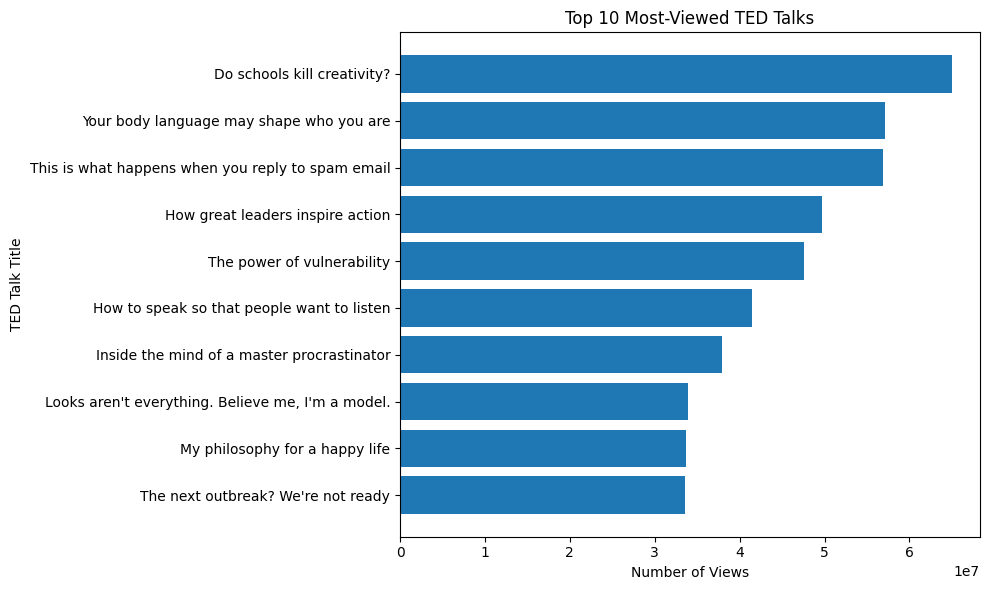

In [18]:
top_talks = df.nlargest(10, "views")[["title", "speaker_1", "views"]]

plt.figure(figsize=(10, 6))
plt.barh(top_talks["title"][::-1], top_talks["views"][::-1])

plt.xlabel("Number of Views")
plt.ylabel("TED Talk Title")
plt.title("Top 10 Most-Viewed TED Talks")
plt.tight_layout()
plt.show()

speaker_1
Alex Gendler        117619583
Sir Ken Robinson     84380518
James Veitch         78843641
Simon Sinek          62661183
Brené Brown          61285977
Bill Gates           57107176
Amy Cuddy            57074270
Julian Treasure      54799681
Hans Rosling         39871561
Tim Urban            37976820
Name: views, dtype: int64


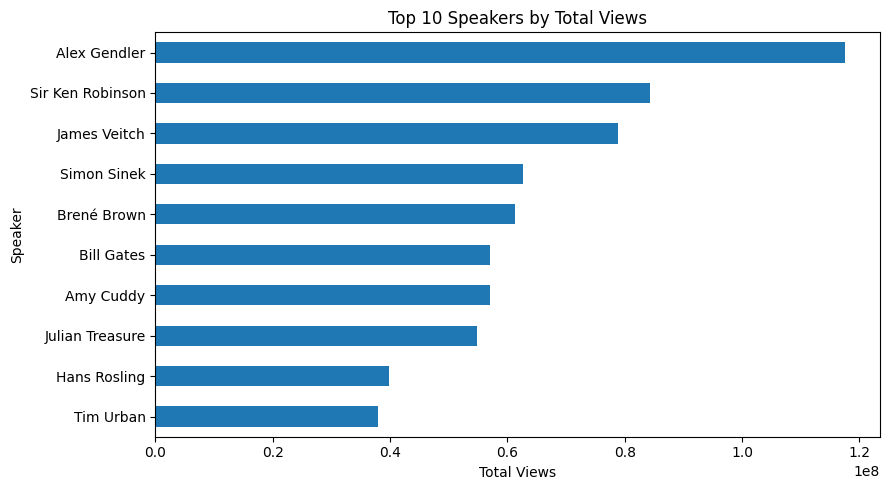

In [19]:
top_speakers = (
    df.groupby("speaker_1")["views"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_speakers)
top_speakers.sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.xlabel("Total Views")
plt.ylabel("Speaker")
plt.title("Top 10 Speakers by Total Views")
plt.tight_layout()
plt.show()

In [20]:
import ast
from collections import Counter

topic_counts = Counter()

for topics in df["topics"].dropna():
    try:
        parsed_topics = ast.literal_eval(topics)
        if isinstance(parsed_topics, list):
            topic_counts.update(parsed_topics)
    except (ValueError, SyntaxError):
        pass

topic_df = pd.DataFrame(
    topic_counts.most_common(10),
    columns=["Topic", "Talk Count"]
)

topic_df

,Topic,Talk Count
0,science,993
1,technology,979
2,culture,680
3,TEDx,581
4,global issues,574
5,TED-Ed,563
6,society,557
7,design,518
8,social change,512
9,animation,487


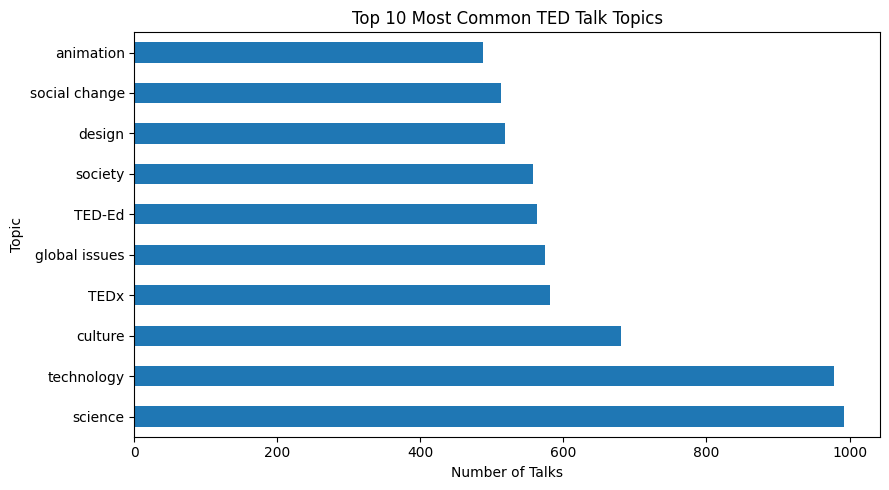

In [21]:
topic_df.plot(
    x="Topic",
    y="Talk Count",
    kind="barh",
    figsize=(9, 5),
    legend=False
)

plt.xlabel("Number of Talks")
plt.title("Top 10 Most Common TED Talk Topics")
plt.tight_layout()
plt.show()

TED Talk Duration Analysis
count    4005.00
mean       12.07
std         6.03
min         1.00
25%         6.55
50%        12.30
75%        16.23
max        65.37
Name: duration_minutes, dtype: float64


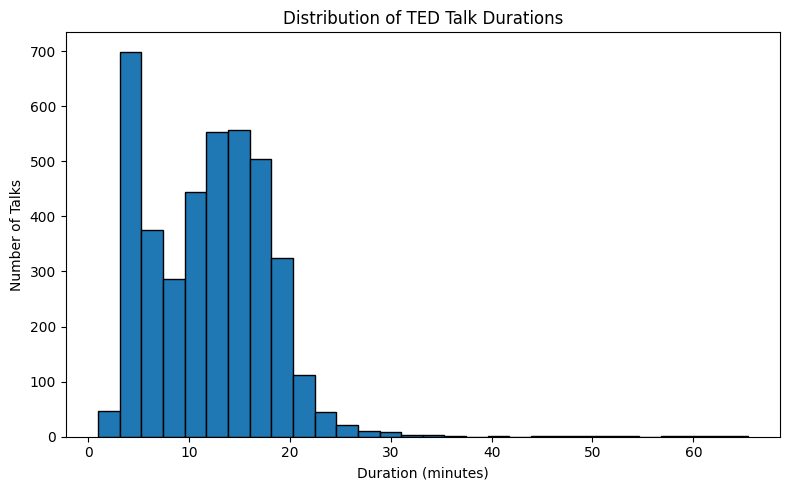

In [22]:
# Convert duration from seconds to minutes
df["duration_minutes"] = df["duration"] / 60

# Display duration statistics
print("TED Talk Duration Analysis")
print(df["duration_minutes"].describe().round(2))

plt.figure(figsize=(8, 5))

plt.hist(df["duration_minutes"], bins=30, edgecolor="black")

plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Durations")

plt.tight_layout()
plt.show()

published_year
2006     49
2007    119
2008    185
2009    215
2010    230
2011    255
2012    303
2013    242
2014    240
2015    220
2016    242
2017    315
2018    477
2019    702
2020    211
Name: count, dtype: int64


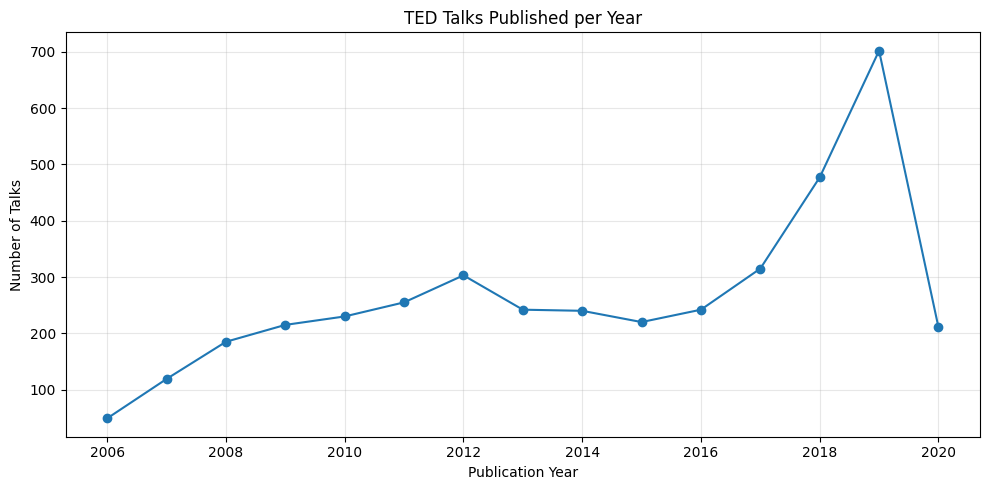

In [23]:
# Extract publication year
df["published_year"] = df["published_date"].dt.year

# Count talks published each year
yearly_talks = df["published_year"].value_counts().sort_index()

print(yearly_talks)

plt.figure(figsize=(10, 5))

plt.plot(yearly_talks.index, yearly_talks.values, marker="o")

plt.xlabel("Publication Year")
plt.ylabel("Number of Talks")
plt.title("TED Talks Published per Year")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Views statistics:
count        4005.00
mean      2148005.57
std       3451225.52
min             0.00
25%        882069.00
50%       1375508.00
75%       2133110.00
max      65051954.00
Name: views, dtype: float64

Comments statistics:
count    4005.00
mean      135.50
std       253.07
min         0.00
25%        17.00
50%        68.00
75%       162.00
max      6449.00
Name: comments, dtype: float64

Correlation between views and comments: 0.46


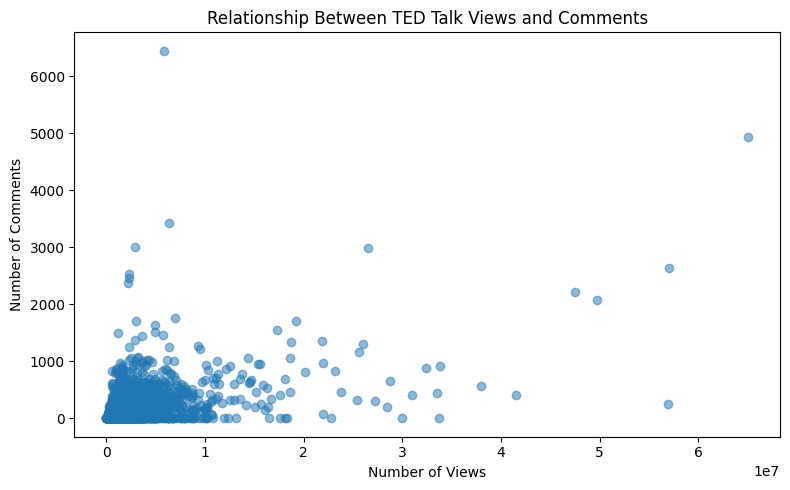

In [24]:
# Summary statistics for views and comments
print("Views statistics:")
print(df["views"].describe().round(2))

print("\nComments statistics:")
print(df["comments"].describe().round(2))

# Calculate correlation
correlation = df["views"].corr(df["comments"])

print("\nCorrelation between views and comments:", round(correlation, 3))

plt.figure(figsize=(8, 5))

plt.scatter(df["views"], df["comments"], alpha=0.5)

plt.xlabel("Number of Views")
plt.ylabel("Number of Comments")
plt.title("Relationship Between TED Talk Views and Comments")

plt.tight_layout()
plt.show()

In [25]:
output_folder = r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01"

top_talks.to_csv(output_folder + r"\top_10_talks.csv", index=False)
topic_df.to_csv(output_folder + r"\top_10_topics.csv", index=False)

print("EDA result tables saved successfully!")

EDA result tables saved successfully!


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import ast
from collections import Counter

file_path = Path(
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (4005, 19)
Columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']


Average topics per talk: 7.92

Talks by number of topics:
topic_count
1       8
2      51
3     204
4     383
5     573
6     482
7     503
8     418
9     318
10    258
11    194
12    128
13    118
14     92
15     63
16     59
17     37
18     34
19     15
20     21
21     15
22     11
23      7
24      4
25      4
26      1
27      2
28      1
33      1
Name: count, dtype: int64


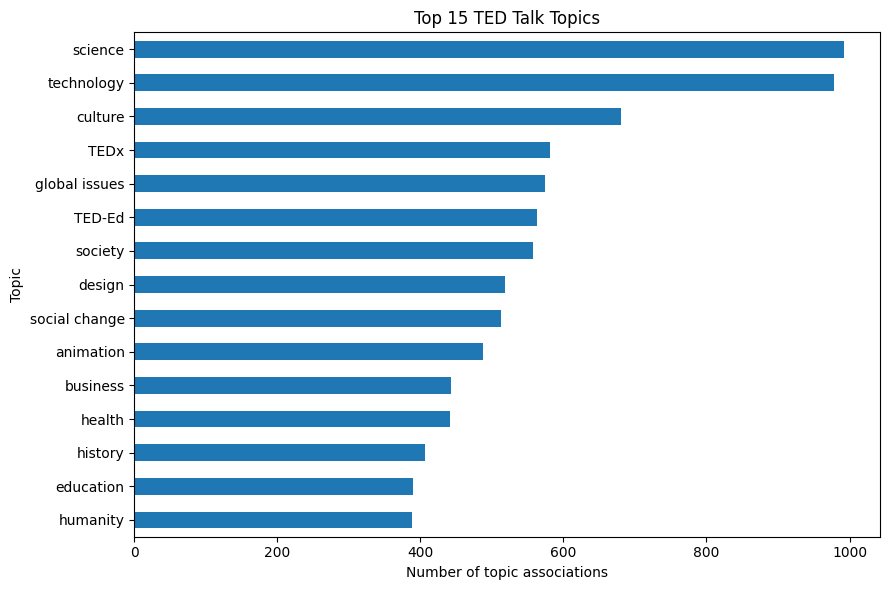

In [27]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

def parse_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []

df["topics_list"] = df["topics"].apply(parse_list)
df["topic_count"] = df["topics_list"].apply(len)

print("Average topics per talk:", round(df["topic_count"].mean(), 2))
print("\nTalks by number of topics:")
print(df["topic_count"].value_counts().sort_index())

topic_counts = Counter(
    topic.strip()
    for topics in df["topics_list"]
    for topic in topics
    if isinstance(topic, str) and topic.strip()
)

top_15_topics = pd.Series(topic_counts).nlargest(15).sort_values()

top_15_topics.plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 TED Talk Topics")
plt.xlabel("Number of topic associations")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()

Unique primary speakers: 3274

Speakers with multiple talks:
speaker_1
Alex Gendler            34
Iseult Gillespie        19
Emma Bryce              12
Daniel Finkel           11
Hans Rosling            10
Alex Rosenthal          10
Juan Enriquez            9
Greg Gage                9
Chris Anderson           8
Dan Ariely               7
Marco Tempest            7
 Rives                   6
Stewart Brand            6
Bill Gates               6
Elizabeth Cox            6
Joy Lin                  6
Nicholas Negroponte      5
Eve Ensler               5
Jacqueline Novogratz     5
Paola Antonelli          5
Name: count, dtype: int64


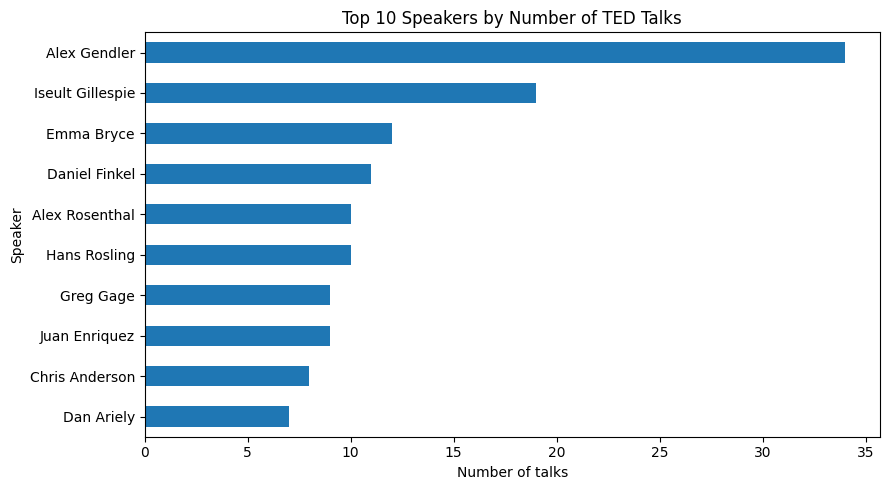

Unique names in all_speakers (comma-separated approximation): 3412


In [28]:
# Count unique speakers in the primary-speaker column
unique_primary_speakers = df["speaker_1"].dropna().nunique()
print("Unique primary speakers:", unique_primary_speakers)

# Count talks by primary speaker
speaker_talk_counts = df["speaker_1"].dropna().value_counts()

print("\nSpeakers with multiple talks:")
print(speaker_talk_counts[speaker_talk_counts > 1].head(20))

top_10_speakers = speaker_talk_counts.head(10).sort_values()

top_10_speakers.plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Speakers by Number of TED Talks")
plt.xlabel("Number of talks")
plt.ylabel("Speaker")
plt.tight_layout()
plt.show()

# Count unique names across all_speakers as well
all_speaker_names = set()

for value in df["all_speakers"].dropna():
    if str(value).strip().lower() != "unknown":
        all_speaker_names.update(
            name.strip() for name in str(value).split(",")
            if name.strip()
        )

print("Unique names in all_speakers (comma-separated approximation):",
      len(all_speaker_names))

In [29]:
text_columns = [
    "title", "description", "transcript", "about_speakers"
]

for col in text_columns:
    text = df[col].fillna("").astype(str).str.strip()
    word_counts = text.str.split().str.len()

    print(f"\n--- {col} ---")
    print("Empty entries:", (text == "").sum())
    print("Entries under 10 words:", (word_counts < 10).sum())
    print("Entries over 5000 words:", (word_counts > 5000).sum())
    print("Average word count:", round(word_counts.mean(), 2))
    print("Median word count:", word_counts.median())

# Save individual word counts for further analysis
df["title_word_count"] = df["title"].fillna("").astype(str).str.split().str.len()
df["description_word_count"] = df["description"].fillna("").astype(str).str.split().str.len()
df["transcript_word_count"] = df["transcript"].fillna("").astype(str).str.split().str.len()

# Transcript quality indicators
transcript_text = df["transcript"].fillna("").astype(str).str.strip()
print("\nTranscript quality checks")
print("Empty transcripts:", (transcript_text == "").sum())
print("Transcripts under 50 words:",
      (transcript_text.str.split().str.len() < 50).sum())
print("Transcripts over 5000 words:",
      (transcript_text.str.split().str.len() > 5000).sum())


--- title ---
Empty entries: 0
Entries under 10 words: 3470
Entries over 5000 words: 0
Average word count: 6.74
Median word count: 6.0

--- description ---
Empty entries: 0
Entries under 10 words: 1
Entries over 5000 words: 0
Average word count: 58.2
Median word count: 57.0

--- transcript ---
Empty entries: 0
Entries under 10 words: 7
Entries over 5000 words: 22
Average word count: 1796.85
Median word count: 1753.0

--- about_speakers ---
Empty entries: 0
Entries under 10 words: 555
Entries over 5000 words: 0
Average word count: 22.53
Median word count: 22.0

Transcript quality checks
Empty transcripts: 0
Transcripts under 50 words: 10
Transcripts over 5000 words: 22


Mean views: 2148005.57
Median views: 1375508.0
Minimum views: 0
Maximum views: 65051954


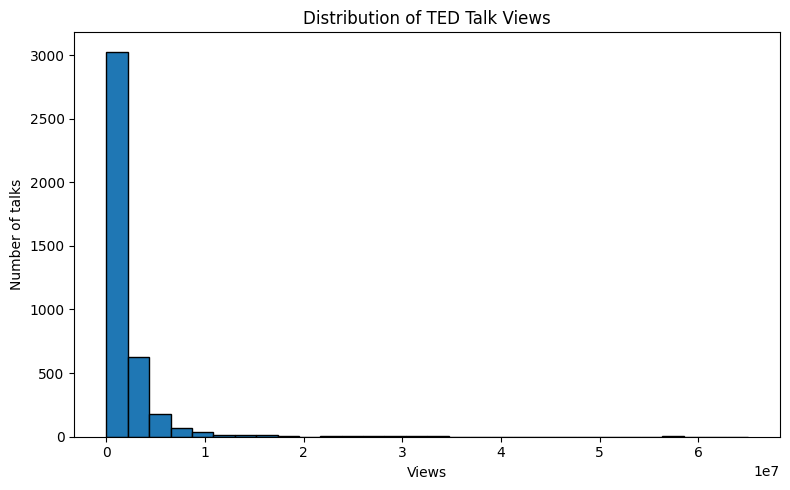

Potential high-view outliers: 393
Upper outlier threshold: 4009671.5
                                                  title         speaker_1  \
4                           Do schools kill creativity?  Sir Ken Robinson   
1296           Your body language may shape who you are         Amy Cuddy   
2062  This is what happens when you reply to spam email      James Veitch   
646                    How great leaders inspire action       Simon Sinek   
796                          The power of vulnerability       Brené Brown   
1724         How to speak so that people want to listen   Julian Treasure   
2108         Inside the mind of a master procrastinator         Tim Urban   
1366  Looks aren't everything. Believe me, I'm a model.   Cameron Russell   
2724                     My philosophy for a happy life         Sam Berns   
1898                 The next outbreak? We're not ready        Bill Gates   

         views  
4     65051954  
1296  57074270  
2062  56932551  
646   49730580 

In [2]:
views = pd.to_numeric(df["views"], errors="coerce").dropna()

print("Mean views:", round(views.mean(), 2))
print("Median views:", views.median())
print("Minimum views:", views.min())
print("Maximum views:", views.max())

plt.figure(figsize=(8, 5))
plt.hist(views, bins=30, edgecolor="black")
plt.title("Distribution of TED Talk Views")
plt.xlabel("Views")
plt.ylabel("Number of talks")
plt.tight_layout()
plt.show()

# IQR outlier detection
q1, q3 = views.quantile([0.25, 0.75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

print("Potential high-view outliers:", (views > upper_limit).sum())
print("Upper outlier threshold:", upper_limit)

print(df.loc[views[views > upper_limit].index,
             ["title", "speaker_1", "views"]]
      .sort_values("views", ascending=False).head(10))

In [30]:
duration = pd.to_numeric(df["duration"], errors="coerce")

print("Mean duration (minutes):", round(duration.mean() / 60, 2))
print("Median duration (minutes):", round(duration.median() / 60, 2))
print("Minimum duration (minutes):", duration.min() / 60)
print("Maximum duration (minutes):", duration.max() / 60)
print("Missing or non-numeric durations:", duration.isna().sum())
print("Zero or negative durations:", (duration <= 0).sum())

print("\nInvalid duration records:")
print(df.loc[duration.isna() | (duration <= 0),
             ["title", "duration"]].head(20))

Mean duration (minutes): 12.07
Median duration (minutes): 12.3
Minimum duration (minutes): 1.0
Maximum duration (minutes): 65.36666666666666
Missing or non-numeric durations: 0
Zero or negative durations: 0

Invalid duration records:
Empty DataFrame
Columns: [title, duration]
Index: []


Earliest publication date: 2006-06-27 00:00:00
Latest publication date: 2020-04-30 00:00:00
Missing publication dates: 0
Missing recorded dates: 1

Talks published per year:
published_date
2006     49
2007    119
2008    185
2009    215
2010    230
2011    255
2012    303
2013    242
2014    240
2015    220
2016    242
2017    315
2018    477
2019    702
2020    211
Name: count, dtype: int64


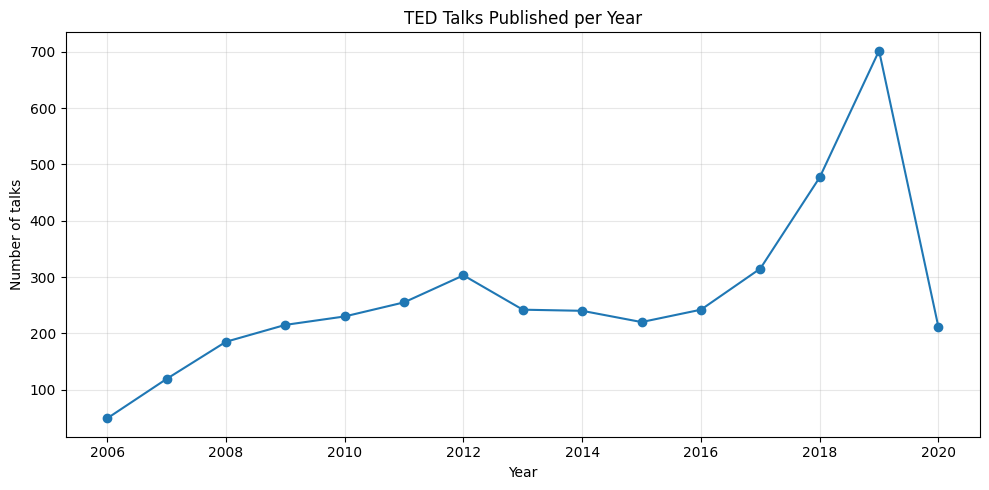

In [31]:
df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce"
)
df["recorded_date"] = pd.to_datetime(
    df["recorded_date"], errors="coerce"
)

print("Earliest publication date:", df["published_date"].min())
print("Latest publication date:", df["published_date"].max())
print("Missing publication dates:", df["published_date"].isna().sum())
print("Missing recorded dates:", df["recorded_date"].isna().sum())

yearly_counts = df["published_date"].dt.year.value_counts().sort_index()
print("\nTalks published per year:")
print(yearly_counts)

yearly_counts.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("TED Talks Published per Year")
plt.xlabel("Year")
plt.ylabel("Number of talks")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
for col in ["native_lang", "available_lang"]:
    print(f"\n--- {col} ---")
    print("Missing values:", df[col].isna().sum())

    values = df[col].fillna("").astype(str).str.strip()
    print("Empty values:", (values == "").sum())
    print("Top 10 values:")
    print(values[values != ""].value_counts().head(10))

# Count languages listed as available, when stored as a list-like string
available_languages = Counter()

for value in df["available_lang"].dropna():
    parsed = parse_list(value)
    if parsed:
        available_languages.update(
            lang.strip() for lang in parsed
            if isinstance(lang, str) and lang.strip()
        )
    else:
        available_languages.update(
            lang.strip() for lang in str(value).split(",")
            if lang.strip()
        )

print("\nMost frequently listed available languages:")
print(available_languages.most_common(10))


--- native_lang ---
Missing values: 0
Empty values: 0
Top 10 values:
native_lang
en       3957
es         27
fr          9
ja          3
hi          2
de          1
pt          1
ko          1
zh-cn       1
ar          1
Name: count, dtype: int64

--- available_lang ---
Missing values: 0
Empty values: 0
Top 10 values:
available_lang
['en']                                                                                                                                                                                                 24
['en', 'es']                                                                                                                                                                                           10
['ar', 'bg', 'de', 'el', 'en', 'es', 'fr', 'he', 'it', 'ja', 'ko', 'nl', 'pl', 'pt-br', 'ro', 'ru', 'tr', 'vi', 'zh-cn', 'zh-tw']                                                                       6
['en', 'es', 'pt']                                        

Top 10 TED Talk Events:
event
TED-Ed     556
TED2017     96
TED2018     96
TED2019     91
TED2014     84
TED2009     81
TED2013     75
TED2015     75
TED2016     75
TED2011     70
Name: count, dtype: int64


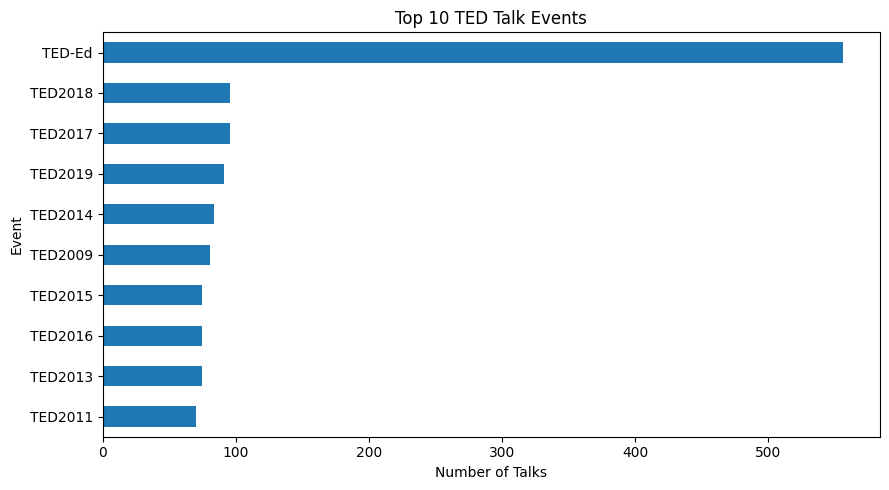


Top 10 Speaker Occupations:
'author']}               70
{0: ['writer']}          53
'activist']}             51
{0: ['author'            49
{0: ['journalist']}      47
{0: ['writer'            44
{0: ['entrepreneur']}    42
{0: ['artist']}          41
{0: ['architect']}       38
{0: ['designer']}        37
dtype: int64


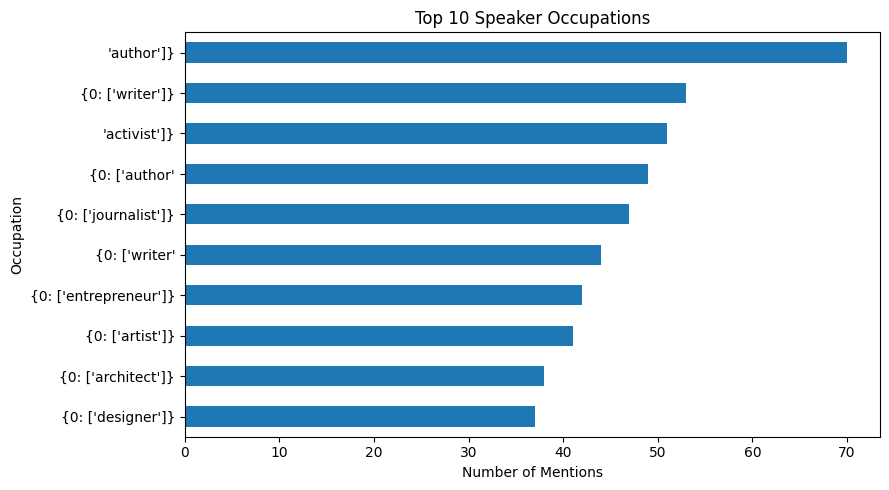

In [5]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Function to safely parse list-like values
def parse_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []

# ==============================
# 1. EVENT ANALYSIS
# ==============================

events = df["event"].fillna("").astype(str).str.strip()
events = events[events != ""]

event_counts = events.value_counts()

print("Top 10 TED Talk Events:")
print(event_counts.head(10))

# Plot top 10 events
event_counts.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 TED Talk Events")
plt.xlabel("Number of Talks")
plt.ylabel("Event")
plt.tight_layout()
plt.show()


# ==============================
# 2. OCCUPATION ANALYSIS
# ==============================

occupation_counts = Counter()

for value in df["occupations"].dropna():

    # Skip unknown values
    if str(value).strip().lower() == "unknown":
        continue

    # Parse occupation lists
    parsed = parse_list(value)

    if parsed:
        occupation_counts.update(
            item.strip()
            for item in parsed
            if isinstance(item, str) and item.strip()
        )
    else:
        # Handle comma-separated text
        occupation_counts.update(
            item.strip()
            for item in str(value).split(",")
            if item.strip()
        )

# Select the top 10 occupations
top_occupations = pd.Series(
    dict(occupation_counts)
).nlargest(10)

print("\nTop 10 Speaker Occupations:")
print(top_occupations)

# Plot top 10 occupations
top_occupations.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 Speaker Occupations")
plt.xlabel("Number of Mentions")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

Mean comments: 135.5
Median comments: 68.0
Minimum comments: 0.0
Maximum comments: 6449.0
Missing comments: 0

Top 10 most-commented talks:
                                         title          speaker_1  \
94                            Militant atheism    Richard Dawkins   
4                  Do schools kill creativity?   Sir Ken Robinson   
617         Science can answer moral questions         Sam Harris   
1735         How do you explain consciousness?     David Chalmers   
197                       My stroke of insight  Jill Bolte Taylor   
1296  Your body language may shape who you are          Amy Cuddy   
911               Taking imagination seriously     Janet Echelman   
799                       On reading the Koran    Lesley Hazleton   
631               The danger of science denial    Michael Specter   
796                 The power of vulnerability        Brené Brown   

      comments_numeric  
94              6449.0  
4               4931.0  
617             3424.0  


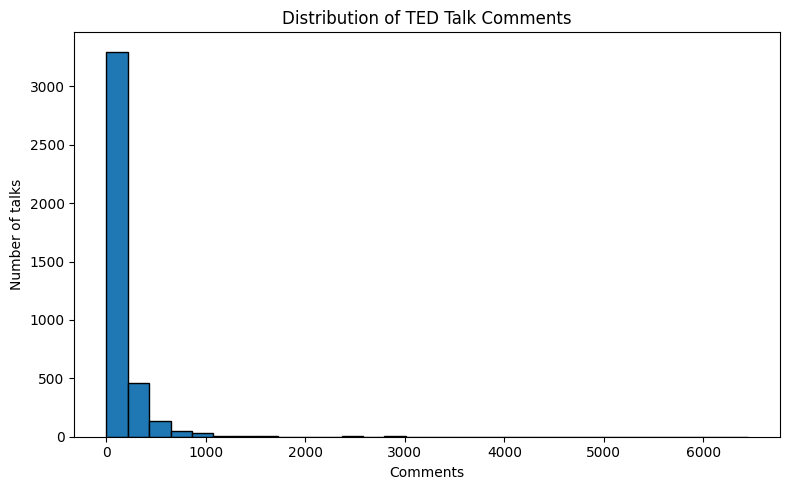

Potential high-comment outliers: 297


In [11]:
comments = pd.to_numeric(df["comments"], errors="coerce")

print("Mean comments:", round(comments.mean(), 2))
print("Median comments:", comments.median())
print("Minimum comments:", comments.min())
print("Maximum comments:", comments.max())
print("Missing comments:", comments.isna().sum())

print("\nTop 10 most-commented talks:")
print(df.assign(comments_numeric=comments)
      .nlargest(10, "comments_numeric")[
          ["title", "speaker_1", "comments_numeric"]
      ])

plt.figure(figsize=(8, 5))
plt.hist(comments.dropna(), bins=30, edgecolor="black")
plt.title("Distribution of TED Talk Comments")
plt.xlabel("Comments")
plt.ylabel("Number of talks")
plt.tight_layout()
plt.show()

valid_comments = comments.dropna()
q1, q3 = valid_comments.quantile([0.25, 0.75])
upper_limit = q3 + 1.5 * (q3 - q1)

print("Potential high-comment outliers:",
      (valid_comments > upper_limit).sum())

In [12]:
df["related_talks_list"] = df["related_talks"].apply(parse_list)
df["related_talk_count"] = df["related_talks_list"].apply(len)

print("Average related talks per entry:",
      round(df["related_talk_count"].mean(), 2))
print("Maximum related talks:", df["related_talk_count"].max())

# Match related talk IDs against talk_id in the dataset
talk_ids = set(
    pd.to_numeric(df["talk_id"], errors="coerce").dropna().astype(int)
)

def get_related_id(value):
    try:
        return int(value)
    except (ValueError, TypeError):
        return None

all_references = [
    get_related_id(item)
    for items in df["related_talks_list"]
    for item in items
]
all_references = [x for x in all_references if x is not None]

existing = sum(ref in talk_ids for ref in all_references)
missing = len(all_references) - existing

print("Related talk references:", len(all_references))
print("References found in dataset:", existing)
print("References missing from dataset:", missing)

Average related talks per entry: 0.0
Maximum related talks: 0
Related talk references: 0
References found in dataset: 0
References missing from dataset: 0


In [6]:

import pandas as pd
import re
from pathlib import Path

print("FINAL EDA DATA QUALITY REPORT")
print("-" * 40)
print("Dataset shape:", df.shape)

# Check duplicate records using the original dataset columns.
# Exclude derived columns containing lists.
original_columns = [
    col for col in df.columns
    if col not in [
        "topics_list",
        "related_talks_list",
        "combined_text"
    ]
]

# Convert list/dictionary values to strings for duplicate checking
duplicate_check = df[original_columns].copy()

for col in duplicate_check.columns:
    duplicate_check[col] = duplicate_check[col].apply(
        lambda x: str(x) if isinstance(x, (list, dict, set)) else x
    )

print("Duplicate rows:", duplicate_check.duplicated().sum())

print("\nMissing values by column:")
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() else "No missing values")

# Clean text fields
def clean_text(value):
    if pd.isna(value):
        return ""
    value = str(value)
    value = re.sub(r"<[^>]+>", " ", value)
    value = re.sub(r"\s+", " ", value)
    return value.strip()

for col in ["title", "description", "transcript", "about_speakers"]:
    if col in df.columns:
        df[col] = df[col].apply(clean_text)

# Convert topics into readable text
def topics_to_text(value):
    if isinstance(value, list):
        return " ".join(str(x) for x in value)
    return str(value) if pd.notna(value) else ""

# Create combined text for content-based recommendations
df["combined_text"] = (
    df["title"].fillna("") + " " +
    df["topics"].apply(topics_to_text) + " " +
    df["description"].fillna("") + " " +
    df["transcript"].fillna("")
).str.replace(r"\s+", " ", regex=True).str.strip()

print("\nEmpty combined-text entries:",
      (df["combined_text"] == "").sum())

# Save final cleaned dataset
output_path = Path(
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01"
) / "ted_talks_cleaned.csv"

df.to_csv(output_path, index=False)

print("\nCleaned dataset saved successfully!")
print("Location:", output_path)
print("Final dataset shape:", df.shape)


FINAL EDA DATA QUALITY REPORT
----------------------------------------
Dataset shape: (4005, 21)
Duplicate rows: 0

Missing values by column:
recorded_date    1
dtype: int64

Empty combined-text entries: 0

Cleaned dataset saved successfully!
Location: C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv
Final dataset shape: (4005, 22)


In [ ]:
## Module 3: Feature Engineering and TF-IDF Vectorization

In [5]:
import pandas as pd
import numpy as np
import re
import ast
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import save_npz

# Load the cleaned dataset
DATA_PATH = Path(
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (4005, 19)

Available columns:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [4]:
required_columns = [
    "title", "topics", "description", "transcript"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required dataset columns: {missing_columns}"
    )

print("Missing values in recommendation columns:")
print(df[required_columns].isna().sum())

print("\nMetadata columns available:")
print([
    col for col in [
        "talk_id", "speaker_1", "views",
        "duration", "url", "published_date"
    ]
    if col in df.columns
])

Missing values in recommendation columns:
title          0
topics         0
description    0
transcript     0
dtype: int64

Metadata columns available:
['talk_id', 'speaker_1', 'views', 'duration', 'url', 'published_date']


In [5]:
def clean_text(value):
    """Clean a text field and safely handle missing values."""
    if isinstance(value, list):
        value = " ".join(str(item) for item in value)

    if pd.isna(value):
        return ""

    value = str(value)
    value = re.sub(r"<[^>]+>", " ", value)  # Remove HTML tags
    value = re.sub(r"\s+", " ", value)      # Normalize whitespace

    return value.strip()


def topics_to_text(value):
    """Convert topics stored as lists or list-like strings to text."""
    if isinstance(value, list):
        return " ".join(str(item) for item in value)

    if pd.isna(value):
        return ""

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list):
                return " ".join(str(item) for item in parsed)
        except (ValueError, SyntaxError):
            pass

    return clean_text(value)


df["title_clean"] = df["title"].apply(clean_text)
df["topics_clean"] = df["topics"].apply(topics_to_text)
df["description_clean"] = df["description"].apply(clean_text)
df["transcript_clean"] = df["transcript"].apply(clean_text)

print("Text preprocessing completed.")
display(
    df[[
        "title", "topics_clean",
        "description_clean", "transcript_clean"
    ]].head(3)
)

Text preprocessing completed.


,title,topics_clean,description_clean,transcript_clean
0,Averting the climate crisis,alternative energy cars climate change culture...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,The best stats you've ever seen,Africa Asia Google demo economics global issue...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,Simplicity sells,computers entertainment interface design media...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."


In [10]:
df["recommendation_text"] = (
    (df["title_clean"] + " ") * 3
    + (df["topics_clean"] + " ") * 2
    + df["description_clean"] + " "
    + df["transcript_clean"]
).str.strip()

empty_text_count = df["recommendation_text"].eq("").sum()

print("Talks with no usable text:", empty_text_count)
print(
    "Talks with usable text:",
    len(df) - empty_text_count
)

display(df[["title", "recommendation_text"]].head(3))

Talks with no usable text: 0
Talks with usable text: 4005


,title,recommendation_text
0,Averting the climate crisis,Averting the climate crisis Averting the clima...
1,The best stats you've ever seen,The best stats you've ever seen The best stats...
2,Simplicity sells,Simplicity sells Simplicity sells Simplicity s...


In [11]:
df = df.loc[
    df["recommendation_text"].ne("")
].copy()

df = df.reset_index(drop=True)

print("Talks retained for recommendation:", len(df))
print("Data shape:", df.shape)

assert df["recommendation_text"].notna().all()
assert df["recommendation_text"].ne("").all()

Talks retained for recommendation: 4005
Data shape: (4005, 24)


In [8]:
df["recommendation_text"] = (
    (df["title_clean"] + " ") * 3
    + (df["topics_clean"] + " ") * 2
    + df["description_clean"] + " "
    + df["transcript_clean"]
).str.strip()

print("Recommendation text created!")
print("Empty text rows:", df["recommendation_text"].eq("").sum())

display(df[["title", "recommendation_text"]].head(3))

Recommendation text created!
Empty text rows: 0


,title,recommendation_text
0,Averting the climate crisis,Averting the climate crisis Averting the clima...
1,The best stats you've ever seen,The best stats you've ever seen The best stats...
2,Simplicity sells,Simplicity sells Simplicity sells Simplicity s...


In [3]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Imports successful!")

Imports successful!


In [4]:
import pandas as pd
import numpy as np
import re
import ast
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded: (4005, 19)
Columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']


In [5]:
def clean_text(value):
    if isinstance(value, list):
        value = " ".join(str(x) for x in value)

    if pd.isna(value):
        return ""

    value = re.sub(r"<[^>]+>", " ", str(value))
    value = re.sub(r"\s+", " ", value)
    return value.strip()


def topics_to_text(value):
    if isinstance(value, list):
        return " ".join(str(x) for x in value)

    if pd.isna(value):
        return ""

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list):
                return " ".join(str(x) for x in parsed)
        except (ValueError, SyntaxError):
            pass

    return clean_text(value)


required = ["title", "topics", "description", "transcript"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Dataset is missing columns: {missing}")

df["title_clean"] = df["title"].apply(clean_text)
df["topics_clean"] = df["topics"].apply(topics_to_text)
df["description_clean"] = df["description"].apply(clean_text)
df["transcript_clean"] = df["transcript"].apply(clean_text)

df["recommendation_text"] = (
    (df["title_clean"] + " ") * 3
    + (df["topics_clean"] + " ") * 2
    + df["description_clean"] + " "
    + df["transcript_clean"]
).str.strip()

df = df[df["recommendation_text"].ne("")].copy()
df.reset_index(drop=True, inplace=True)

print("Recommendation text created successfully!")
print("Number of usable talks:", len(df))

display(df[["title", "recommendation_text"]].head(3))

Recommendation text created successfully!
Number of usable talks: 4005


,title,recommendation_text
0,Averting the climate crisis,Averting the climate crisis Averting the clima...
1,The best stats you've ever seen,The best stats you've ever seen The best stats...
2,Simplicity sells,Simplicity sells Simplicity sells Simplicity s...


In [16]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    sublinear_tf=True,
    dtype=np.float32
)

tfidf_matrix = tfidf.fit_transform(
    df["recommendation_text"]
)

print("TF-IDF vectorization completed!")
print("Matrix shape:", tfidf_matrix.shape)
print("Number of talks:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("Matrix type:", type(tfidf_matrix))

total_entries = (
    tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
)

sparsity = (
    100 * (1 - tfidf_matrix.nnz / total_entries)
    if total_entries else 0
)

print(f"Matrix sparsity: {sparsity:.2f}%")

TF-IDF vectorization completed!
Matrix shape: (4005, 20000)
Number of talks: 4005
Number of features: 20000
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix sparsity: 97.60%


In [9]:
from pathlib import Path
import joblib
from scipy.sparse import save_npz, load_npz

DATA_PATH = Path(
    r"C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\ted_talks_cleaned.csv"
)

OUTPUT_DIR = DATA_PATH.parent / "recommendation_artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained TF-IDF vectorizer
joblib.dump(
    tfidf,
    OUTPUT_DIR / "tfidf_vectorizer.joblib"
)

# Save the TF-IDF feature matrix
save_npz(
    OUTPUT_DIR / "tfidf_matrix.npz",
    tfidf_matrix
)

# Save talk details
metadata_columns = [
    col for col in [
        "talk_id", "title", "speaker_1", "topics",
        "description", "url", "views", "duration",
        "published_date"
    ]
    if col in df.columns
]

df[metadata_columns].to_csv(
    OUTPUT_DIR / "talk_metadata.csv",
    index=False
)

# Save processed text
df[["title", "recommendation_text"]].to_csv(
    OUTPUT_DIR / "preprocessed_talk_text.csv",
    index=False
)

print("All files saved successfully!")
print("Saved location:", OUTPUT_DIR)

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

All files saved successfully!
Saved location: C:\Users\lucky\Downloads\Ted_dataset\2020-05-01\recommendation_artifacts
preprocessed_talk_text.csv
talk_metadata.csv
tfidf_matrix.npz
tfidf_vectorizer.joblib


In [10]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

def recommend_talks(talk_title, top_n=5):

    if not isinstance(top_n, int) or top_n < 1:
        raise ValueError("top_n must be a positive integer.")

    # Find the selected TED Talk
    titles = df["title"].fillna("").astype(str)

    matches = df.index[
        titles.str.casefold()
        == str(talk_title).strip().casefold()
    ].tolist()

    if not matches:
        raise ValueError(
            "Title not found. Copy an exact title from df['title']."
        )

    talk_index = matches[0]

    # Calculate similarity against every talk
    scores = cosine_similarity(
        tfidf_matrix[talk_index],
        tfidf_matrix
    ).ravel()

    # Do not recommend the selected talk itself
    scores[talk_index] = -1

    result_count = min(top_n, len(df) - 1)

    top_indices = np.argsort(scores)[::-1][:result_count]

    recommendations = df.iloc[top_indices].copy()
    recommendations["similarity_score"] = scores[top_indices]

    columns_to_show = [
        col for col in [
            "title",
            "speaker_1",
            "topics",
            "similarity_score",
            "url"
        ]
        if col in recommendations.columns
    ]

    return recommendations[columns_to_show].reset_index(drop=True)


print("Recommendation function created successfully!")

Recommendation function created successfully!


In [11]:
# Display some available TED Talk titles
display(df[["title"]].head(15))

# Select the first TED Talk as a test
example_title = df.loc[0, "title"]

print("Selected TED Talk:", example_title)

# Generate five recommendations
recommendations = recommend_talks(
    example_title,
    top_n=5
)

display(recommendations)

,title
0,Averting the climate crisis
1,The best stats you've ever seen
2,Simplicity sells
3,Greening the ghetto
4,Do schools kill creativity?
5,Behind the design of Seattle's library
6,Letting go of God
7,Let's teach religion -- all religion -- in sch...
8,A life of purpose
9,My wish: A global day of film


Selected TED Talk: Averting the climate crisis


,title,speaker_1,topics,similarity_score,url
0,New thinking on the climate crisis,Al Gore,"['activism', 'climate change', 'global issues'...",0.213039,https://www.ted.com/talks/al_gore_new_thinking...
1,How we can turn the tide on climate,Chris Anderson,"['climate change', 'environment', 'activism', ...",0.201284,https://www.ted.com/talks/christiana_figueres_...
2,What comes after An Inconvenient Truth?,Al Gore,"['alternative energy', 'climate change', 'ener...",0.196300,https://www.ted.com/talks/al_gore_what_comes_a...
3,The case for optimism on climate change,Al Gore,"['climate change', 'weather', 'science', 'alte...",0.193996,https://www.ted.com/talks/al_gore_the_case_for...
4,Salvation (and profit) in greentech,John Doerr,"['climate change', 'environment', 'global issu...",0.182262,https://www.ted.com/talks/john_doerr_salvation...


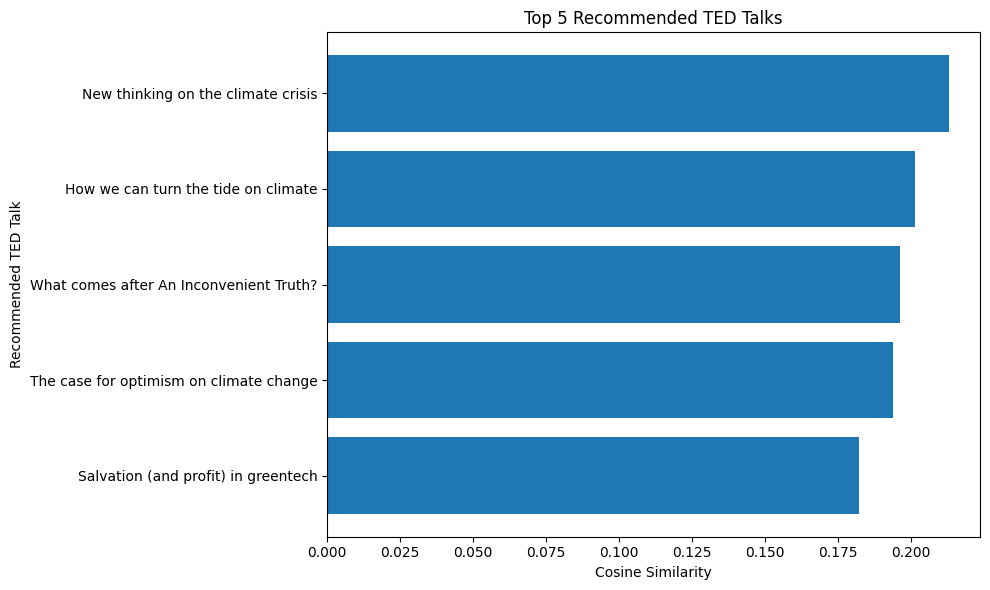

In [12]:
import matplotlib.pyplot as plt

if not recommendations.empty:

    plot_data = recommendations.sort_values(
        "similarity_score"
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_data["title"].astype(str),
        plot_data["similarity_score"]
    )

    plt.xlabel("Cosine Similarity")
    plt.ylabel("Recommended TED Talk")
    plt.title("Top 5 Recommended TED Talks")

    plt.tight_layout()
    plt.show()

else:
    print("No recommendations available.")

,Word or phrase,TF-IDF score
0,climate crisis,0.128228
1,al gore,0.098584
2,gore,0.096539
3,global warming,0.091286
4,carbon,0.090237
5,emissions,0.088996
6,trucks,0.088767
7,science sustainability,0.086807
8,al,0.086801
9,warming,0.086120


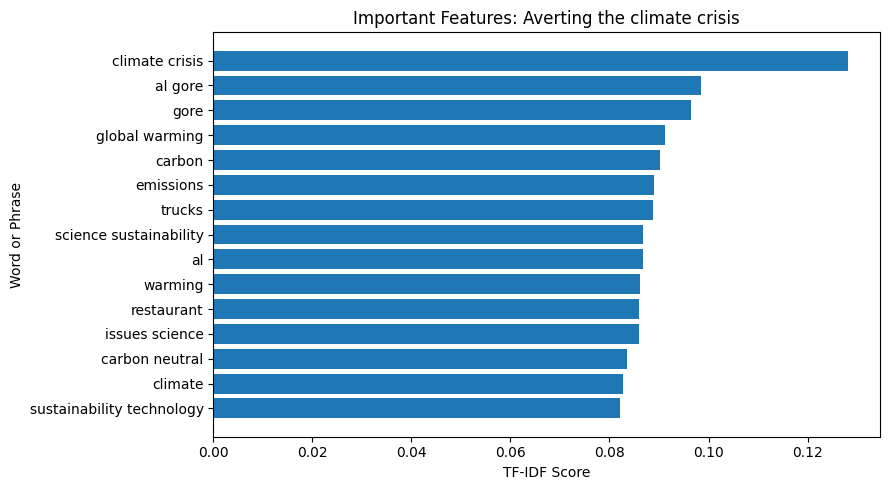

In [13]:
feature_names = tfidf.get_feature_names_out()

talk_index = 0

talk_vector = tfidf_matrix[talk_index].toarray().ravel()

top_indices = np.argsort(talk_vector)[::-1][:15]

important_features = pd.DataFrame({
    "Word or phrase": feature_names[top_indices],
    "TF-IDF score": talk_vector[top_indices]
})

important_features = important_features[
    important_features["TF-IDF score"] > 0
]

display(important_features)

plt.figure(figsize=(9, 5))

plt.barh(
    important_features["Word or phrase"][::-1],
    important_features["TF-IDF score"][::-1]
)

plt.xlabel("TF-IDF Score")
plt.ylabel("Word or Phrase")
plt.title(f"Important Features: {df.loc[talk_index, 'title']}")

plt.tight_layout()
plt.show()

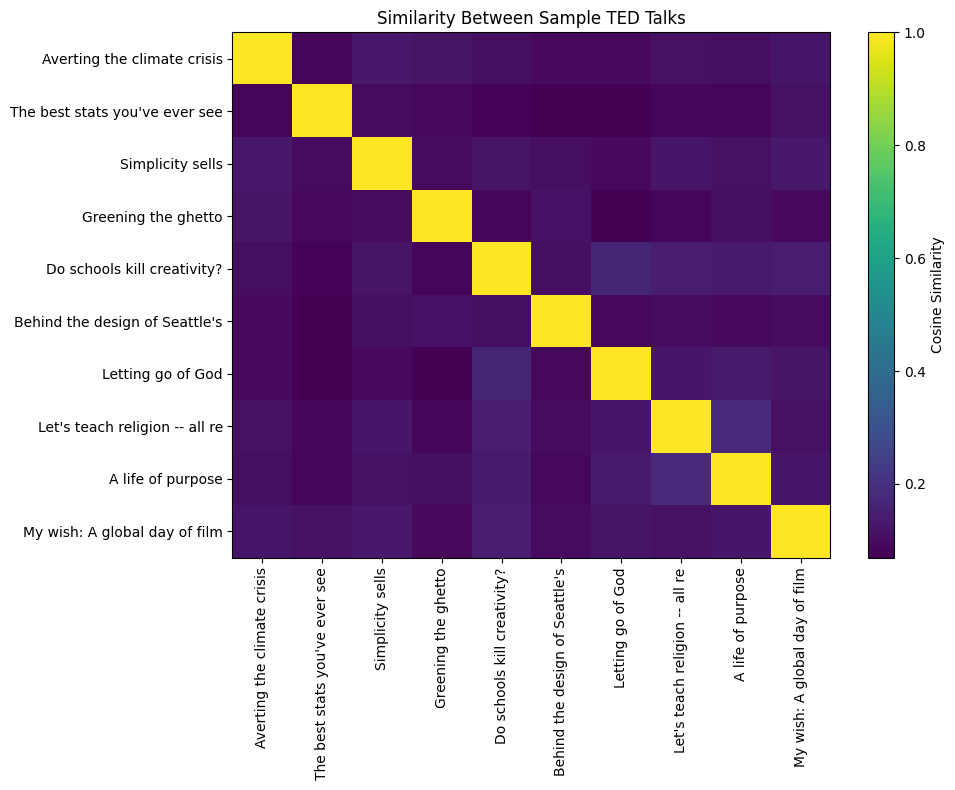

In [14]:
sample_size = min(10, len(df))

sample_matrix = tfidf_matrix[:sample_size]

similarity_matrix = cosine_similarity(sample_matrix)

sample_titles = [
    str(title)[:30]
    for title in df["title"].iloc[:sample_size]
]

plt.figure(figsize=(10, 8))

plt.imshow(similarity_matrix, aspect="auto")

plt.colorbar(label="Cosine Similarity")

plt.xticks(
    range(sample_size),
    sample_titles,
    rotation=90
)

plt.yticks(
    range(sample_size),
    sample_titles
)

plt.title("Similarity Between Sample TED Talks")
plt.tight_layout()
plt.show()

In [15]:
loaded_tfidf = joblib.load(
    OUTPUT_DIR / "tfidf_vectorizer.joblib"
)

loaded_matrix = load_npz(
    OUTPUT_DIR / "tfidf_matrix.npz"
)

loaded_metadata = pd.read_csv(
    OUTPUT_DIR / "talk_metadata.csv"
)

print("Vectorizer loaded:", type(loaded_tfidf).__name__)
print("Original matrix shape:", tfidf_matrix.shape)
print("Loaded matrix shape:", loaded_matrix.shape)
print("Metadata shape:", loaded_metadata.shape)

assert loaded_matrix.shape == tfidf_matrix.shape
assert len(loaded_metadata) == loaded_matrix.shape[0]

print("\nAll saved artifacts verified successfully!")

Vectorizer loaded: TfidfVectorizer
Original matrix shape: (4005, 20000)
Loaded matrix shape: (4005, 20000)
Metadata shape: (4005, 9)

All saved artifacts verified successfully!
